# 🐕 Dog Breed Classification & Detection (ระบบจำแนกและตีกรอบสายพันธุ์สุนัข)

สมุดบันทึกนี้ถูกออกแบบใหม่ให้ **แยกส่วนการเทรน (Training) ออกจากส่วนการใช้งาน (Inference)** อย่างสมบูรณ์:
- 💾 **เก็บบันทึกผลการเทรนแยกแต่ละรอบอัตโนมัติ:** ไม่มีรอบไหนสูญหายหรือถูกเขียนทับ
- ⚡ **เปิดใช้งานได้ทันทีโดยไม่ต้องเทรนใหม่:** มีระบบ Auto-Loader โหลดโมเดลที่ดีที่สุดให้ตั้งแต่เริ่มต้น
- 🎯 **ฟังก์ชันครบถ้วน:** ทำนายภาพเดี่ยว, กราฟ Top 5, ทดสอบ 10 สายพันธุ์, ตีกรอบ Bounding Box พร้อมค่า Precision, และกล้อง Webcam สด

---


### 1. นำเข้าไลบรารีและตรวจสอบข้อมูลสายพันธุ์จาก `data.yaml`

In [2]:
import os
import glob
import yaml
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import torch

# กำหนด Path ของชุดข้อมูล
dataset_dir = r"C:\Users\perth\Downloads\My First Project.v1i.folder"
runs_dir = os.path.join(dataset_dir, "runs_breed_classification")
os.makedirs(runs_dir, exist_ok=True)

yaml_path = os.path.join(dataset_dir, "data.yaml")
with open(yaml_path, 'r', encoding='utf-8') as f:
    data_cfg = yaml.safe_load(f)

print(f"✅ โหลด data.yaml สำเร็จ! จำนวนสายพันธุ์ทั้งหมด: {data_cfg['nc']} สายพันธุ์")
print("รายชื่อสายพันธุ์ในระบบ:", ", ".join(list(data_cfg['names'].values())))


✅ โหลด data.yaml สำเร็จ! จำนวนสายพันธุ์ทั้งหมด: 10 สายพันธุ์
รายชื่อสายพันธุ์ในระบบ: Beagle, Boxer, Chihuahua, Cocker_Spaniel, German_Shorthaired, Great_Pyrenees, Pomeranian, Pug, Saint_Bernard, Samoyed


### 2. ตรวจสอบประวัติการเทรนทั้งหมด และโหลดโมเดลที่ดีที่สุดอัตโนมัติ (Auto Model Loader)
*(เซลล์นี้จะสแกนหาโมเดลที่เคยเทรนไว้ทุกรอบ แล้วโหลด Best Model ให้ทันทีใน 1 วินาที โดยไม่ต้องเทรนใหม่)*


In [3]:
def scan_training_runs(runs_path):
    """สแกนหารอบการเทรนทั้งหมดที่บันทึกไว้ และดึงค่าสถิติความแม่นยำ"""
    history = []
    if not os.path.exists(runs_path):
        return history

    for item in os.listdir(runs_path):
        run_folder = os.path.join(runs_path, item)
        if not os.path.isdir(run_folder):
            continue

        best_weights = os.path.join(run_folder, "weights", "best.pt")
        last_weights = os.path.join(run_folder, "weights", "last.pt")
        csv_file = os.path.join(run_folder, "results.csv")

        info = {
            "Run Name": item,
            "Folder": run_folder,
            "Best Weights": best_weights if os.path.exists(best_weights) else None,
            "Last Weights": last_weights if os.path.exists(last_weights) else None,
            "Epochs": "-",
            "Top-1 Acc": "-",
            "Top-5 Acc": "-",
            "Time": os.path.getmtime(run_folder)
        }

        if os.path.exists(csv_file):
            try:
                df = pd.read_csv(csv_file)
                df.columns = [c.strip() for c in df.columns]
                last_row = df.iloc[-1]
                info["Epochs"] = int(last_row.get("epoch", len(df)))
                if "metrics/accuracy_top1" in df.columns:
                    info["Top-1 Acc"] = f"{last_row['metrics/accuracy_top1']:.2%}"
                if "metrics/accuracy_top5" in df.columns:
                    info["Top-5 Acc"] = f"{last_row['metrics/accuracy_top5']:.2%}"
            except Exception:
                pass

        history.append(info)

    # เรียงลำดับตามรอบที่แก้ไขล่าสุด
    history.sort(key=lambda x: x["Time"], reverse=True)
    return history

# สแกนประวัติการเทรน
run_history = scan_training_runs(runs_dir)

print("=" * 70)
print("📊 ประวัติการเทรนทั้งหมดที่บันทึกไว้ในโฟลเดอร์ runs_breed_classification:")
print("=" * 70)

selected_model_path = None

if run_history:
    table_data = []
    for h in run_history:
        status = "✅ มีไฟล์ best.pt" if h["Best Weights"] else "❌ ไม่มีไฟล์โมเดล"
        table_data.append({
            "ชื่อรอบการเทรน (Run Name)": h["Run Name"],
            "จำนวน Epochs": h["Epochs"],
            "Top-1 Accuracy": h["Top-1 Acc"],
            "Top-5 Accuracy": h["Top-5 Acc"],
            "สถานะโมเดล": status
        })
    df_table = pd.DataFrame(table_data)
    print(df_table.to_string(index=False))
    print("=" * 70)

    # เลือกรอบล่าสุดที่มีไฟล์ best.pt
    for h in run_history:
        if h["Best Weights"]:
            selected_model_path = h["Best Weights"]
            selected_run_name = h["Run Name"]
            break

if selected_model_path:
    trained_model = YOLO(selected_model_path)
    print(f"🎯 โหลดโมเดลพร้อมใช้งานสำเร็จ: '{selected_run_name}'")
    print(f"📁 Path: {selected_model_path}")
    print("💡 คุณสามารถข้ามขั้นตอนการเทรนใน Step 3 แล้วไปรัน Step 4 เป็นต้นไปได้ทันทีครับ!")
else:
    trained_model = YOLO("yolov8n-cls.pt")
    print("⚠️ ยังไม่พบโมเดลที่เทรนสำเร็จ จะใช้ 'yolov8n-cls.pt' เป็นโมเดลตั้งต้น")
    print("💡 หากต้องการเริ่มเทรน ให้เปิดสวิตช์ใน Step 3 ด้านล่างแล้วสั่งรันครับ")


📊 ประวัติการเทรนทั้งหมดที่บันทึกไว้ในโฟลเดอร์ runs_breed_classification:
ชื่อรอบการเทรน (Run Name)  จำนวน Epochs Top-1 Accuracy Top-5 Accuracy       สถานะโมเดล
      run_20261105_125907            45         82.13%         98.39% ✅ มีไฟล์ best.pt
            dog_10_breeds            15         82.73%         99.40% ✅ มีไฟล์ best.pt
🎯 โหลดโมเดลพร้อมใช้งานสำเร็จ: 'run_20261105_125907'
📁 Path: C:\Users\perth\Downloads\My First Project.v1i.folder\runs_breed_classification\run_20261105_125907\weights\best.pt
💡 คุณสามารถข้ามขั้นตอนการเทรนใน Step 3 แล้วไปรัน Step 4 เป็นต้นไปได้ทันทีครับ!


### 3. (เลือกทำเมื่อต้องการเทรนเพิ่ม) สั่ง Train รอบใหม่ หรือ Train ต่อจากเดิม (Resume)
> **💡 ระบบป้องกันการเผลอรันเทรนซ้ำ:**  
> - ค่าเริ่มต้นของ **`START_TRAINING = False`**  
> - หากคุณมีโมเดลอยู่แล้วและต้องการแค่ **ทดสอบภาพ / เปิดกล้อง ให้ข้ามเซลล์นี้ไปได้เลย**  
> - เมื่อต้องการเทรนรอบใหม่ ให้เปลี่ยนเป็น **`START_TRAINING = True`** โดยแต่ละรอบจะถูกบันทึกแยกโฟลเดอร์ใหม่อัตโนมัติ ไม่เขียนทับรอบเดิม


In [21]:
import datetime

# ==============================================================================
# ⚙️ สวิตช์ควบคุมการเทรน
# ==============================================================================
START_TRAINING = False       # เปลี่ยนเป็น True เฉพาะเวลาต้องการสั่งเทรนจริงๆ เท่านั้น!

# ตั้งค่าการเทรนรอบใหม่:
TRAIN_CONFIG = {
    "run_name": "auto",      # "auto" = ตั้งชื่อตามวันเวลา (เช่น run_20261105_1430) หรือตั้งเอง เช่น "exp_v2_epochs30"
    "epochs": 45,            # จำนวนรอบที่ต้องการเทรน
    "batch": 32,             # Batch size
    "imgsz": 224,            # ขนาดรูปภาพ
    "resume": False,         # True = เทรนต่อจาก checkpoint ล่าสุด (last.pt), False = เทรนรอบใหม่
}

if not START_TRAINING:
    print("⏸️ การเทรนถูกปิดอยู่ (START_TRAINING = False)")
    print("💡 โมเดลพร้อมใช้งานจาก Step 2 แล้ว สามารถเลื่อนไปรัน Step 4, 5, 6, 7 หรือ 8 ได้เลยครับ!")
else:
    # ตรวจสอบการใช้งาน CUDA GPU
    if torch.cuda.is_available():
        device = 0
        print(f"⚡ ตรวจพบ GPU: {torch.cuda.get_device_name(0)}")
        print(f"🚀 สั่งเทรนผ่านโหมด: CUDA (device={device})")
    else:
        device = "cpu"
        print("⚠️ ใช้งาน CPU สำหรับการเทรน")

    # กำหนดชื่อรอบการเทรน
    if TRAIN_CONFIG["run_name"] == "auto":
        now_str = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
        run_name = f"run_{now_str}"
    else:
        run_name = TRAIN_CONFIG["run_name"]

    print(f"📁 บันทึกผลลัพธ์รอบนี้ในโฟลเดอร์: {run_name}")

    if TRAIN_CONFIG["resume"]:
        # โหมดเทรนต่อจาก checkpoint เดิม
        latest_last = None
        for h in run_history:
            if h["Last Weights"]:
                latest_last = h["Last Weights"]
                break
        if latest_last:
            print(f"🔄 กำลังเทรนต่อจาก Checkpoint: {latest_last}")
            model = YOLO(latest_last)
            train_results = model.train(resume=True)
        else:
            print("❌ ไม่พบ checkpoint เดิมสำหรับเทรนต่อ จะเริ่มเทรนรอบใหม่")
            model = YOLO('yolov8n-cls.pt')
            train_results = model.train(
                data=dataset_dir,
                epochs=TRAIN_CONFIG["epochs"],
                imgsz=TRAIN_CONFIG["imgsz"],
                batch=TRAIN_CONFIG["batch"],
                device=device,
                workers=2,
                project=runs_dir,
                name=run_name,
                exist_ok=False  # ป้องกันการเขียนทับรอบเก่า!
            )
    else:
        # โหมดเทรนรอบใหม่
        print(f"🚀 เริ่มต้นการเทรนรอบใหม่ ({TRAIN_CONFIG['epochs']} epochs)...")
        model = YOLO('yolov8n-cls.pt')
        train_results = model.train(
            data=dataset_dir,
            epochs=TRAIN_CONFIG["epochs"],
            imgsz=TRAIN_CONFIG["imgsz"],
            batch=TRAIN_CONFIG["batch"],
            device=device,
            workers=2,
            project=runs_dir,
            name=run_name,
            exist_ok=False  # ป้องกันการเขียนทับรอบเก่า!
        )

    print("🎉 การเทรนรอบนี้เสร็จสิ้นเรียบร้อยแล้ว!")
    # อัปเดต trained_model เป็นโมเดลล่าสุด
    new_best = os.path.join(runs_dir, run_name, "weights", "best.pt")
    if os.path.exists(new_best):
        trained_model = YOLO(new_best)
        print(f"🎯 อัปเดตโมเดลใช้งานเป็นรอบใหม่แล้ว: {new_best}")


⏸️ การเทรนถูกปิดอยู่ (START_TRAINING = False)
💡 โมเดลพร้อมใช้งานจาก Step 2 แล้ว สามารถเลื่อนไปรัน Step 4, 5, 6, 7 หรือ 8 ได้เลยครับ!


### 4. ดูกราฟความแม่นยำและตารางสรุปผลการเทรน (Training Metrics & Confusion Matrix)
แสดงผลลัพธ์ของรอบการเทรนล่าสุด เช่น กราฟ Loss, กราฟ Top-1 Accuracy และ Confusion Matrix


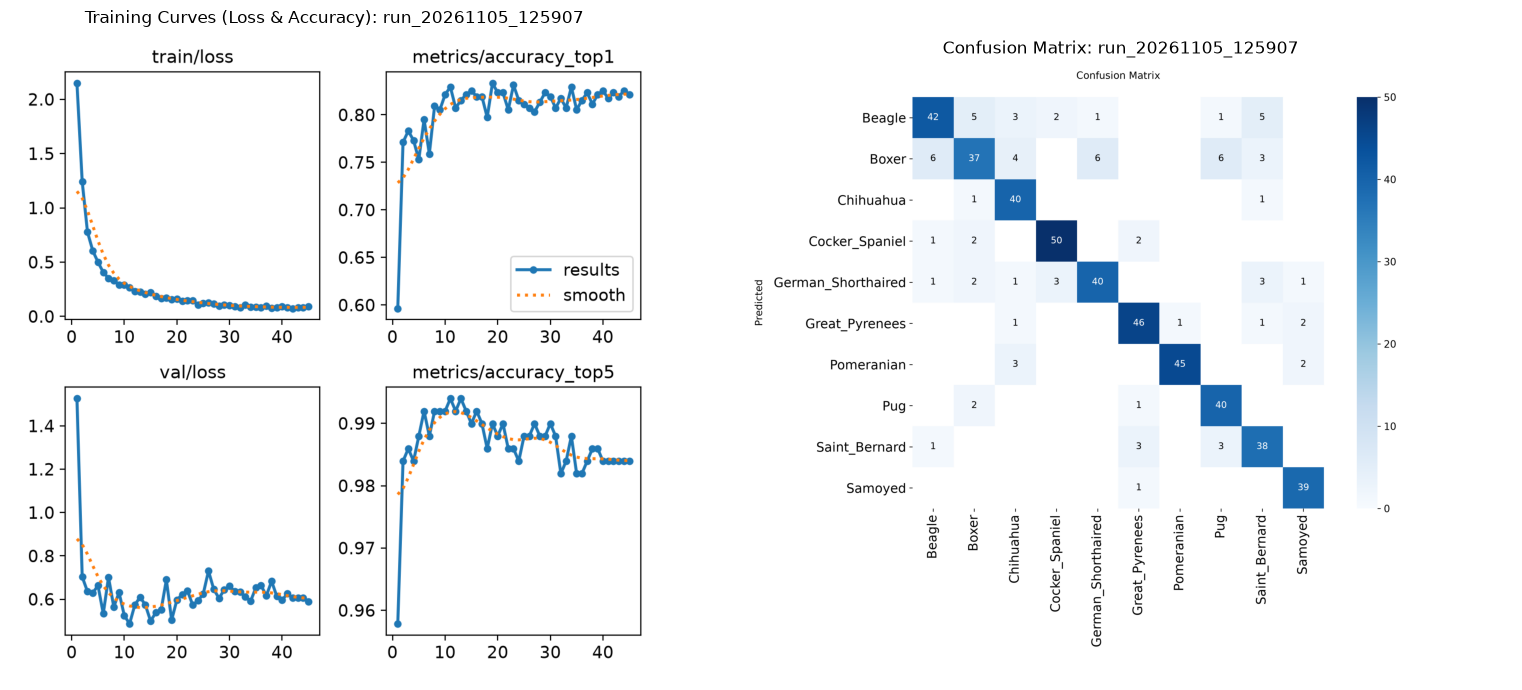

In [2]:
# ค้นหาภาพสรุปผลของรอบการเทรนล่าสุด
if run_history:
    latest_run_folder = run_history[0]["Folder"]
    results_png = os.path.join(latest_run_folder, "results.png")
    matrix_png = os.path.join(latest_run_folder, "confusion_matrix.png")

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    if os.path.exists(results_png):
        axes[0].imshow(Image.open(results_png))
        axes[0].set_title(f"Training Curves (Loss & Accuracy): {os.path.basename(latest_run_folder)}")
        axes[0].axis("off")
    else:
        axes[0].text(0.5, 0.5, "ยังไม่มีไฟล์ results.png", ha='center')
        axes[0].axis("off")

    if os.path.exists(matrix_png):
        axes[1].imshow(Image.open(matrix_png))
        axes[1].set_title(f"Confusion Matrix: {os.path.basename(latest_run_folder)}")
        axes[1].axis("off")
    else:
        axes[1].text(0.5, 0.5, "ยังไม่มีไฟล์ confusion_matrix.png", ha='center')
        axes[1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("ยังไม่มีประวัติการเทรนให้แสดงผล")


### 4.1 ตารางค่าวัดผลแบบเจาะลึก (Precision, Recall, F1-Score, Confusion Matrix)
เซลล์นี้จะประเมินผลไฟล์ `best.pt` กับภาพในชุด **Validation (หรือ Test)** ทีละภาพ พร้อมแจกแจง:
- **Precision / Recall / F1-Score** แยกรายสายพันธุ์ทั้ง 10 สายพันธุ์
- **Top-1 / Top-5 Accuracy** และค่าเฉลี่ย Macro/Weighted
- **Confusion Matrix Heatmap** และคู่สายพันธุ์ที่โมเดลทายสับสนมากที่สุด


In [ ]:
from evaluate_metrics import run_evaluation

# สั่งประเมินผลอย่างละเอียด (สามารถเปลี่ยน split='valid' หรือ split='test' ได้ตามต้องการ):
metrics_result = run_evaluation(weights_path=selected_model_path, split='valid')


### 5. ทำนายสายพันธุ์ภาพเดี่ยว + กราฟแท่ง Top 5 Probabilities
นำภาพสุนัขมาทำนาย และแสดงผลค่าความน่าจะเป็นของแต่ละสายพันธุ์


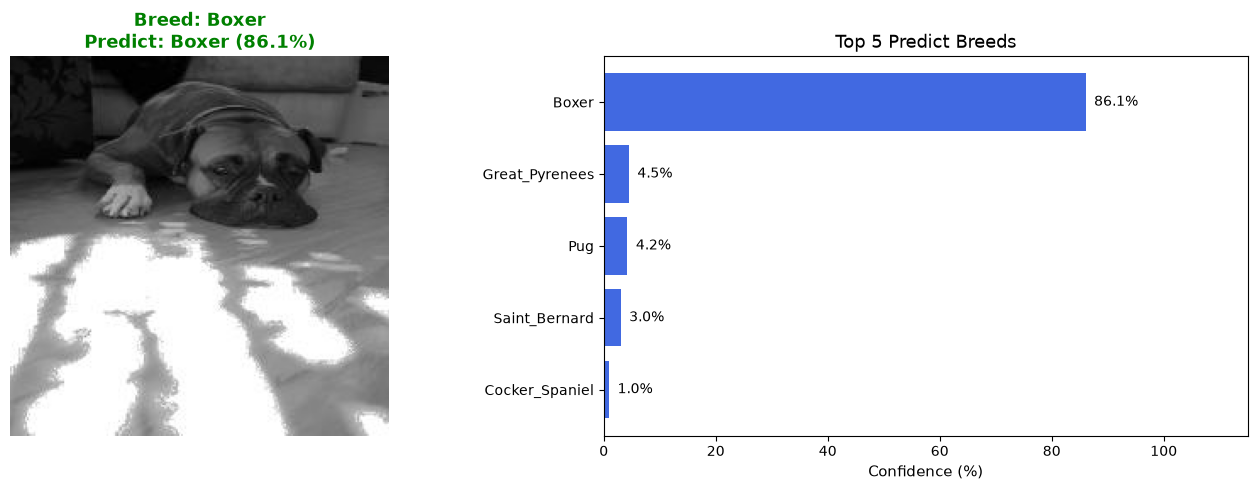

In [3]:
# สุ่มเลือกภาพจากโฟลเดอร์ test
sample_images = glob.glob(os.path.join(dataset_dir, "test", "*", "*.jpg"))
test_img_path = sample_images[99]  # สามารถเปลี่ยน path เป็นรูปใดก็ได้ที่ต้องการทดสอบ

# อ่านสายพันธุ์จริงจากชื่อโฟลเดอร์
actual_breed = os.path.basename(os.path.dirname(test_img_path))

# ทำนายสายพันธุ์
res = trained_model.predict(source=test_img_path, verbose=False)[0]
top1_name = res.names[res.probs.top1]
top1_conf = res.probs.top1conf.item()

# แสดงผลภาพพร้อมกราฟ Top 5 สายพันธุ์
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ฝั่งซ้าย: แสดงรูปภาพ
img = Image.open(test_img_path)
ax1.imshow(img)
is_correct = (top1_name.lower() == actual_breed.lower())
title_color = "green" if is_correct else "red"
ax1.set_title(f"Breed: {actual_breed}\nPredict: {top1_name} ({top1_conf:.1%})", fontsize=13, color=title_color, fontweight="bold")
ax1.axis("off")

# ฝั่งขวา: แสดงกราฟแท่ง Top 5
top5_indices = res.probs.top5
top5_names = [res.names[i] for i in top5_indices][::-1]
top5_values = [res.probs.data[i].item() * 100 for i in top5_indices][::-1]

bars = ax2.barh(top5_names, top5_values, color="royalblue")
ax2.set_xlabel("Confidence (%)", fontsize=11)
ax2.set_title("Top 5 Predict Breeds", fontsize=13)
ax2.set_xlim(0, 115)

# แสดงตัวเลขเปอร์เซ็นต์บนแท่งกราฟ
for bar in bars:
    w = bar.get_width()
    ax2.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=10)

plt.tight_layout()
plt.show()


### 6. ทดสอบภาพตัวอย่างจากทั้ง 10 สายพันธุ์ (Grid Evaluation)

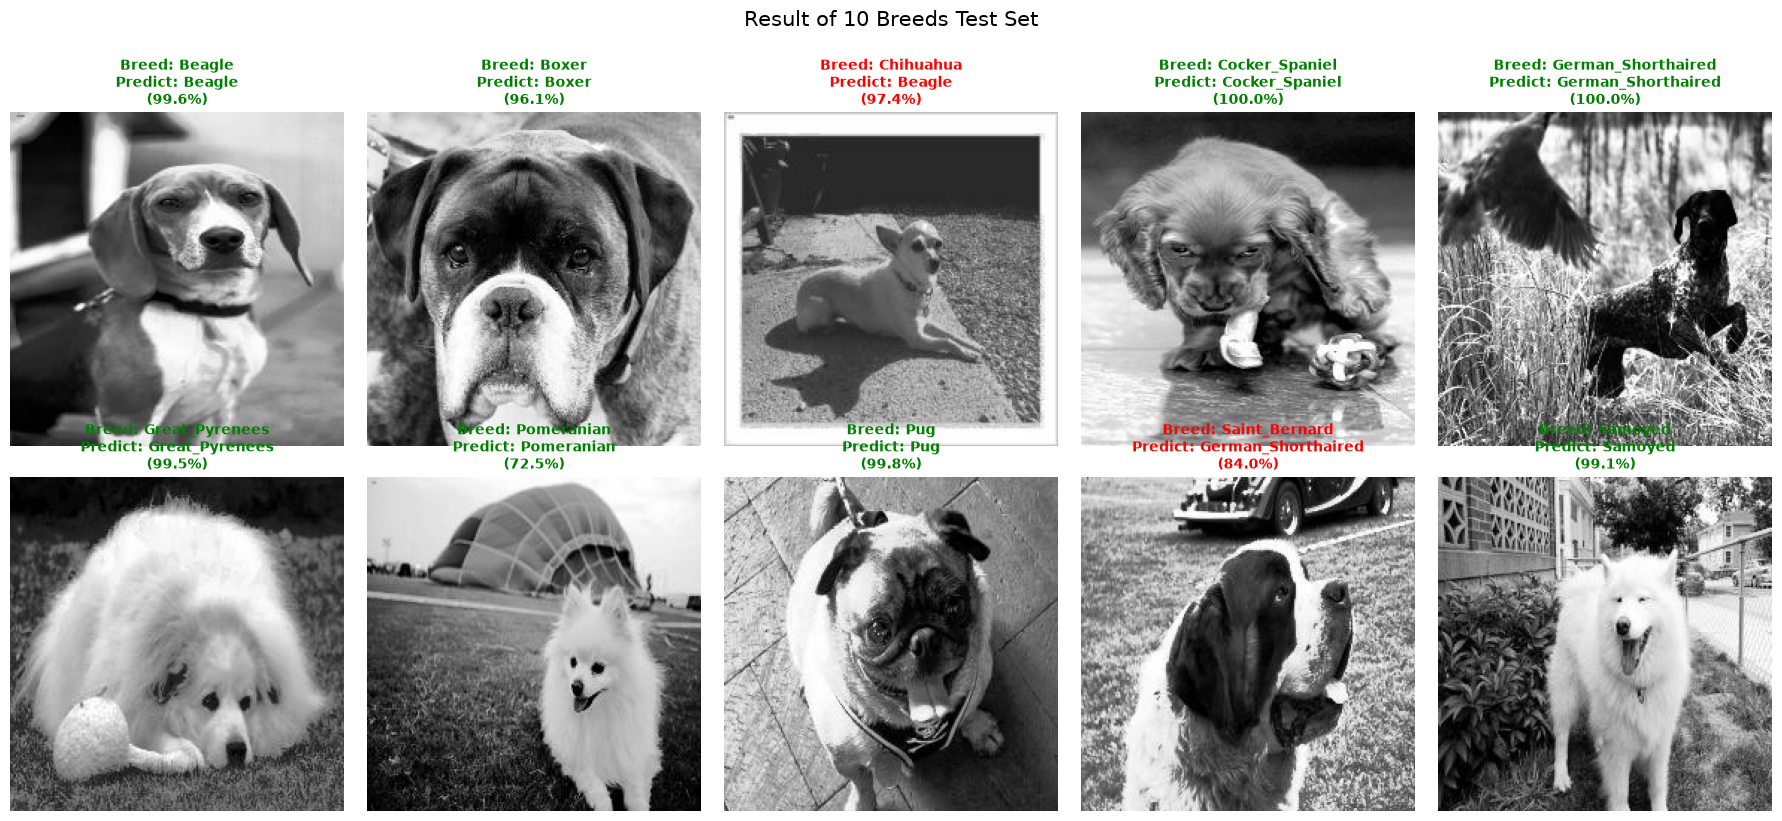

In [5]:
breeds = list(data_cfg['names'].values())
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for idx, breed in enumerate(breeds):
    imgs = glob.glob(os.path.join(dataset_dir, "test", breed, "*.jpg"))
    if not imgs:
        continue
    img_path = imgs[0]

    res = trained_model.predict(img_path, verbose=False)[0]
    pred = res.names[res.probs.top1]
    conf = res.probs.top1conf.item()

    im = Image.open(img_path)
    axes[idx].imshow(im)
    match = (pred.lower() == breed.lower())
    color = "green" if match else "red"
    axes[idx].set_title(f"Breed: {breed}\nPredict: {pred}\n({conf:.1%})", fontsize=10, color=color, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Result of 10 Breeds Test Set", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()


### 7. ตรวจจับตำแหน่ง ตีกรอบ Bounding Box พร้อมระบุสายพันธุ์และ Precision บนภาพ
ผสานการทำงาน 2 ขั้นตอน (Two-Stage Pipeline):
1. **YOLO Detection:** ตรวจจับตำแหน่งตัวสุนัขในภาพและหาพิกัดกรอบ `(x1, y1, x2, y2)`
2. **YOLO Classification:** ส่งเฉพาะส่วนที่ครอปไปวิเคราะห์สายพันธุ์และคำนวณค่า **Precision / Confidence (%)**


📸 ภาพ: Beagle_0117_jpg.rf.d3da94ff5c7d22342ce4b53dc44fafdf.jpg
📍 ตรวจพบสุนัข: 2 ตัว
  [ตัวที่ 1] Bounding Box: [57, 52, 203, 223] | สายพันธุ์: Beagle | Precision: 99.73%
  [ตัวที่ 2] Bounding Box: [29, 52, 150, 223] | สายพันธุ์: Beagle | Precision: 98.62%


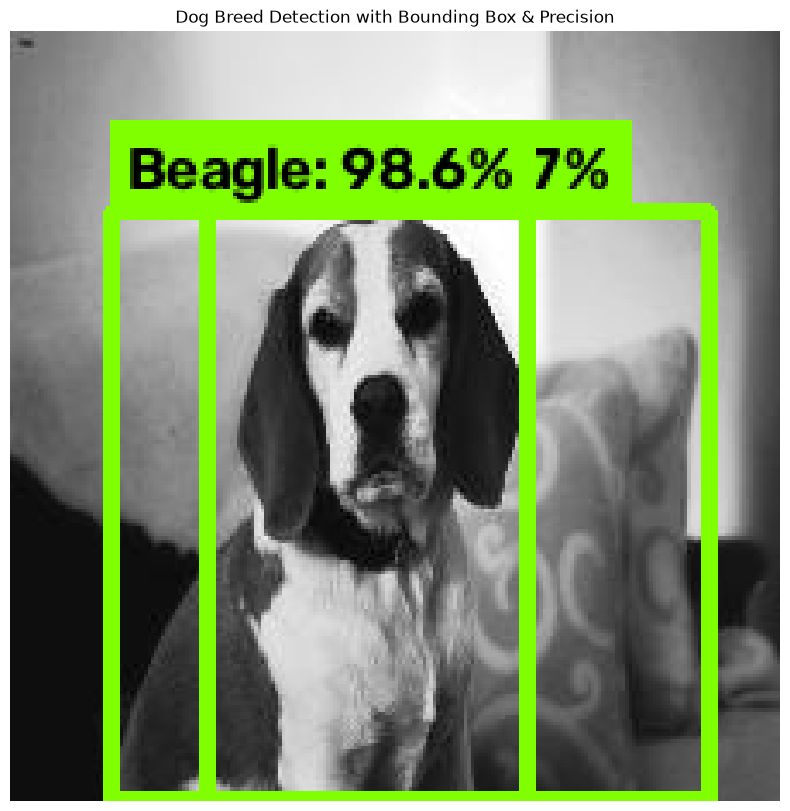

In [10]:
# 1. โหลดโมเดลตรวจจับวัตถุ (Detector)
detector = YOLO('yolov8n.pt')

# 2. เลือกภาพทดสอบ
sample_imgs = glob.glob(os.path.join(dataset_dir, "test", "*", "*.jpg"))
test_img_path = sample_imgs[40]

img_bgr = cv2.imread(test_img_path)
h, w, _ = img_bgr.shape

# ค้นหาตำแหน่งสุนัข (class 16 = dog)
det_res = detector.predict(img_bgr, classes=[16], conf=0.25, verbose=False)[0]

print(f"📸 ภาพ: {os.path.basename(test_img_path)}")
print(f"📍 ตรวจพบสุนัข: {len(det_res.boxes)} ตัว")

for idx, box in enumerate(det_res.boxes):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)

    # ตัดภาพเฉพาะตัวสุนัข
    cropped = img_bgr[y1:y2, x1:x2]
    if cropped.size == 0:
        continue

    # ทายสายพันธุ์
    cls_res = trained_model.predict(cropped, verbose=False)[0]
    breed = cls_res.names[cls_res.probs.top1]
    precision = cls_res.probs.top1conf.item()

    print(f"  [ตัวที่ {idx+1}] Bounding Box: [{x1}, {y1}, {x2}, {y2}] | สายพันธุ์: {breed} | Precision: {precision:.2%}")

    # วาดกรอบสี่เหลี่ยมสีเขียวสด
    cv2.rectangle(img_bgr, (x1, y1), (x2, y2), (0, 255, 127), 3)

    # ป้ายข้อความบอกชื่อสายพันธุ์ + ค่า Precision (%)
    label = f"{breed}: {precision:.1%}"
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
    cv2.rectangle(img_bgr, (x1, max(0, y1 - th - 10)), (x1 + tw + 10, y1), (0, 255, 127), -1)
    cv2.putText(img_bgr, label, (x1 + 5, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

# แสดงผลภาพที่ตีกรอบ
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.title(f"Dog Breed Detection with Bounding Box & Precision")
plt.axis("off")
plt.show()


### 8. เปิดกล้อง Webcam ตีกรอบสุนัขสด พร้อมบอกสายพันธุ์และ Precision บนหน้าจอ
- ตีกรอบ Bounding Box ตามตัวสุนัขแบบ Real-Time
- แสดงป้ายชื่อสายพันธุ์ + ค่า Precision (%) กำกับบนแต่ละกรอบทันที
- หยุดการทำงานได้โดยการกดปุ่ม **Interrupt Kernel / Stop (⏹️)**


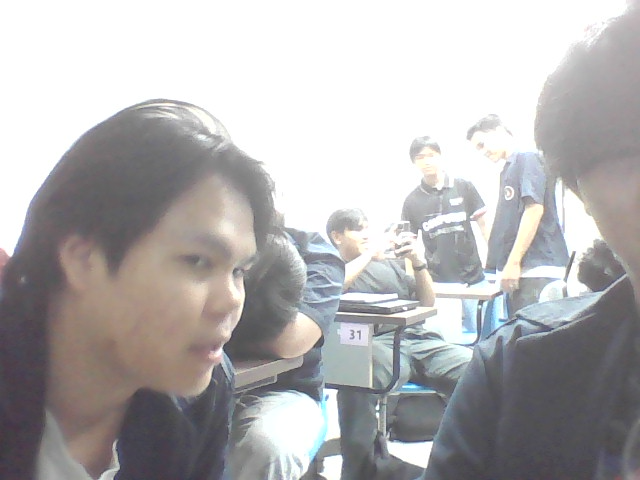

⏹️ สั่งหยุดการทำงานเรียบร้อย
✅ ปิดกล้องเรียบร้อย


In [6]:


from IPython.display import display, clear_output

import os
import glob
import yaml
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import torch

def scan_training_runs(runs_path):
    """สแกนหารอบการเทรนทั้งหมดที่บันทึกไว้ และดึงค่าสถิติความแม่นยำ"""
    history = []
    if not os.path.exists(runs_path):
        return history

    for item in os.listdir(runs_path):
        run_folder = os.path.join(runs_path, item)
        if not os.path.isdir(run_folder):
            continue

        best_weights = os.path.join(run_folder, "weights", "best.pt")
        last_weights = os.path.join(run_folder, "weights", "last.pt")
        csv_file = os.path.join(run_folder, "results.csv")

        info = {
            "Run Name": item,
            "Folder": run_folder,
            "Best Weights": best_weights if os.path.exists(best_weights) else None,
            "Last Weights": last_weights if os.path.exists(last_weights) else None,
            "Epochs": "-",
            "Top-1 Acc": "-",
            "Top-5 Acc": "-",
            "Time": os.path.getmtime(run_folder)
        }

        if os.path.exists(csv_file):
            try:
                df = pd.read_csv(csv_file)
                df.columns = [c.strip() for c in df.columns]
                last_row = df.iloc[-1]
                info["Epochs"] = int(last_row.get("epoch", len(df)))
                if "metrics/accuracy_top1" in df.columns:
                    info["Top-1 Acc"] = f"{last_row['metrics/accuracy_top1']:.2%}"
                if "metrics/accuracy_top5" in df.columns:
                    info["Top-5 Acc"] = f"{last_row['metrics/accuracy_top5']:.2%}"
            except Exception:
                pass

        history.append(info)

    # เรียงลำดับตามรอบที่แก้ไขล่าสุด
    history.sort(key=lambda x: x["Time"], reverse=True)
    return history

# กำหนด Path ของชุดข้อมูล
dataset_dir = r"C:\Users\perth\Downloads\My First Project.v1i.folder"
runs_dir = os.path.join(dataset_dir, "runs_breed_classification")
os.makedirs(runs_dir, exist_ok=True)

yaml_path = os.path.join(dataset_dir, "data.yaml")
with open(yaml_path, 'r', encoding='utf-8') as f:
    data_cfg = yaml.safe_load(f)

print(f"✅ โหลด data.yaml สำเร็จ! จำนวนสายพันธุ์ทั้งหมด: {data_cfg['nc']} สายพันธุ์")
print("รายชื่อสายพันธุ์ในระบบ:", ", ".join(list(data_cfg['names'].values())))

# สแกนประวัติการเทรน
run_history = scan_training_runs(runs_dir)

print("=" * 70)
print("📊 ประวัติการเทรนทั้งหมดที่บันทึกไว้ในโฟลเดอร์ runs_breed_classification:")
print("=" * 70)

selected_model_path = None

if run_history:
    table_data = []
    for h in run_history:
        status = "✅ มีไฟล์ best.pt" if h["Best Weights"] else "❌ ไม่มีไฟล์โมเดล"
        table_data.append({
            "ชื่อรอบการเทรน (Run Name)": h["Run Name"],
            "จำนวน Epochs": h["Epochs"],
            "Top-1 Accuracy": h["Top-1 Acc"],
            "Top-5 Accuracy": h["Top-5 Acc"],
            "สถานะโมเดล": status
        })
    df_table = pd.DataFrame(table_data)
    print(df_table.to_string(index=False))
    print("=" * 70)

    # เลือกรอบล่าสุดที่มีไฟล์ best.pt
    for h in run_history:
        if h["Best Weights"]:
            selected_model_path = h["Best Weights"]
            selected_run_name = h["Run Name"]
            break

if selected_model_path:
    trained_model = YOLO(selected_model_path)
    print(f"🎯 โหลดโมเดลพร้อมใช้งานสำเร็จ: '{selected_run_name}'")
    print(f"📁 Path: {selected_model_path}")
    print("💡 คุณสามารถข้ามขั้นตอนการเทรนใน Step 3 แล้วไปรัน Step 4 เป็นต้นไปได้ทันทีครับ!")
else:
    trained_model = YOLO("yolov8n-cls.pt")
    print("⚠️ ยังไม่พบโมเดลที่เทรนสำเร็จ จะใช้ 'yolov8n-cls.pt' เป็นโมเดลตั้งต้น")
    print("💡 หากต้องการเริ่มเทรน ให้เปิดสวิตช์ใน Step 3 ด้านล่างแล้วสั่งรันครับ")
    


def run_webcam_detection_with_boxes(max_frames=None):
    detector = YOLO('yolov8n.pt')
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("❌ ไม่สามารถเปิดกล้อง Webcam ได้")
        return

    print("🎥 เริ่มต้นตรวจจับ ตีกรอบ และระบุสายพันธุ์ผ่านกล้อง Webcam...")
    print("💡 กดปุ่ม Stop / Interrupt Kernel (⏹️) ด้านบนของ VS Code เพื่อหยุด")

    frame_count = 0
    try:
        while True:
            if max_frames is not None and frame_count >= max_frames:
                break

            ret, frame = cap.read()
            if not ret or frame is None:
                break

            h, w, _ = frame.shape
            # 1. หาพิกัด Bounding Box ของสุนัข
            det_res = detector.predict(frame, classes=[16], conf=0.35, verbose=False)[0]

            # 2. ตีกรอบและวิเคราะห์สายพันธุ์
            for box in det_res.boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w, x2), min(h, y2)

                cropped = frame[y1:y2, x1:x2]
                if cropped.size == 0:
                    continue

                cls_res = trained_model.predict(cropped, verbose=False)[0]
                breed = cls_res.names[cls_res.probs.top1]
                precision = cls_res.probs.top1conf.item()

                # วาดกรอบสี่เหลี่ยม
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 127), 3)

                # วาดป้ายข้อความ (สายพันธุ์ + Precision)
                label = f"{breed}: {precision:.1%}"
                (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
                cv2.rectangle(frame, (x1, max(0, y1 - th - 10)), (x1 + tw + 10, y1), (0, 255, 127), -1)
                cv2.putText(frame, label, (x1 + 5, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

            # แสดงผลใน Notebook
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            clear_output(wait=True)
            display(Image.fromarray(rgb))
            frame_count += 1

    except KeyboardInterrupt:
        print("⏹️ สั่งหยุดการทำงานเรียบร้อย")
    finally:
        cap.release()
        print("✅ ปิดกล้องเรียบร้อย")

# เรียกใช้งานเปิดกล้องตีกรอบแบบสด (รันได้ทันทีโดยไม่ต้องเทรนใหม่!):
run_webcam_detection_with_boxes()


### 9. จับภาพหน้าจอ Windows แบบ Real-Time (Real-Time Windows Screen Capture)
คุณสมบัตินี้จะทำการ **แคปหน้าจอ Windows ของคุณแบบ Real-Time** (เช่น ขณะเปิดดูคลิปวิดีโอสุนัขบน YouTube, ดูรูปในเบราว์เซอร์ หรือดูสตรีม):
- ตีกรอบ Bounding Box รอบตัวสุนัขที่ปรากฏบนหน้าจอทันที
- แสดงชื่อสายพันธุ์และค่า Precision (%) บนกรอบแบบสดๆ
- แสดงค่า **FPS** (อัตราเฟรมต่อวินาที)
- สามารถรันผ่านสคริปต์ [screen_dog_detector.py](file:///C:/Users/perth/Downloads/My%20First%20Project.v1i.folder/screen_dog_detector.py) หรือรันในเซลล์ด้านล่างนี้ได้เลยครับ!


In [12]:
import mss
import time
from IPython.display import display, clear_output

import os
import glob
import yaml
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import torch

# กำหนด Path ของชุดข้อมูล
dataset_dir = r"C:\Users\perth\Downloads\My First Project.v1i.folder"
runs_dir = os.path.join(dataset_dir, "runs_breed_classification")
os.makedirs(runs_dir, exist_ok=True)

yaml_path = os.path.join(dataset_dir, "data.yaml")
with open(yaml_path, 'r', encoding='utf-8') as f:
    data_cfg = yaml.safe_load(f)

print(f"✅ โหลด data.yaml สำเร็จ! จำนวนสายพันธุ์ทั้งหมด: {data_cfg['nc']} สายพันธุ์")
print("รายชื่อสายพันธุ์ในระบบ:", ", ".join(list(data_cfg['names'].values())))

def scan_training_runs(runs_path):
    """สแกนหารอบการเทรนทั้งหมดที่บันทึกไว้ และดึงค่าสถิติความแม่นยำ"""
    history = []
    if not os.path.exists(runs_path):
        return history

    for item in os.listdir(runs_path):
        run_folder = os.path.join(runs_path, item)
        if not os.path.isdir(run_folder):
            continue

        best_weights = os.path.join(run_folder, "weights", "best.pt")
        last_weights = os.path.join(run_folder, "weights", "last.pt")
        csv_file = os.path.join(run_folder, "results.csv")

        info = {
            "Run Name": item,
            "Folder": run_folder,
            "Best Weights": best_weights if os.path.exists(best_weights) else None,
            "Last Weights": last_weights if os.path.exists(last_weights) else None,
            "Epochs": "-",
            "Top-1 Acc": "-",
            "Top-5 Acc": "-",
            "Time": os.path.getmtime(run_folder)
        }

        if os.path.exists(csv_file):
            try:
                df = pd.read_csv(csv_file)
                df.columns = [c.strip() for c in df.columns]
                last_row = df.iloc[-1]
                info["Epochs"] = int(last_row.get("epoch", len(df)))
                if "metrics/accuracy_top1" in df.columns:
                    info["Top-1 Acc"] = f"{last_row['metrics/accuracy_top1']:.2%}"
                if "metrics/accuracy_top5" in df.columns:
                    info["Top-5 Acc"] = f"{last_row['metrics/accuracy_top5']:.2%}"
            except Exception:
                pass

        history.append(info)

    # เรียงลำดับตามรอบที่แก้ไขล่าสุด
    history.sort(key=lambda x: x["Time"], reverse=True)
    return history

# สแกนประวัติการเทรน
run_history = scan_training_runs(runs_dir)

print("=" * 70)
print("📊 ประวัติการเทรนทั้งหมดที่บันทึกไว้ในโฟลเดอร์ runs_breed_classification:")
print("=" * 70)

selected_model_path = None

if run_history:
    table_data = []
    for h in run_history:
        status = "✅ มีไฟล์ best.pt" if h["Best Weights"] else "❌ ไม่มีไฟล์โมเดล"
        table_data.append({
            "ชื่อรอบการเทรน (Run Name)": h["Run Name"],
            "จำนวน Epochs": h["Epochs"],
            "Top-1 Accuracy": h["Top-1 Acc"],
            "Top-5 Accuracy": h["Top-5 Acc"],
            "สถานะโมเดล": status
        })
    df_table = pd.DataFrame(table_data)
    print(df_table.to_string(index=False))
    print("=" * 70)

    # เลือกรอบล่าสุดที่มีไฟล์ best.pt
    for h in run_history:
        if h["Best Weights"]:
            selected_model_path = h["Best Weights"]
            selected_run_name = h["Run Name"]
            break

if selected_model_path:
    trained_model = YOLO(selected_model_path)
    print(f"🎯 โหลดโมเดลพร้อมใช้งานสำเร็จ: '{selected_run_name}'")
    print(f"📁 Path: {selected_model_path}")
    print("💡 คุณสามารถข้ามขั้นตอนการเทรนใน Step 3 แล้วไปรัน Step 4 เป็นต้นไปได้ทันทีครับ!")
else:
    trained_model = YOLO("yolov8n-cls.pt")
    print("⚠️ ยังไม่พบโมเดลที่เทรนสำเร็จ จะใช้ 'yolov8n-cls.pt' เป็นโมเดลตั้งต้น")
    print("💡 หากต้องการเริ่มเทรน ให้เปิดสวิตช์ใน Step 3 ด้านล่างแล้วสั่งรันครับ")


def run_screen_capture_detection(max_frames=None, scale=0.75):
    detector = YOLO('yolov8n.pt')
    sct = mss.mss()
    monitor = sct.monitors[1]  # หน้าจอหลัก
    
    print(f"🖥️ กำลังจับภาพหน้าจอหลัก ({monitor['width']}x{monitor['height']}) แบบ Real-Time...")
    print("💡 กดปุ่ม Stop / Interrupt Kernel (⏹️) ด้านบนของ VS Code เพื่อหยุด")

    colors = [
        (0, 255, 127), (255, 105, 180), (30, 144, 255), (255, 215, 0),
        (255, 69, 0), (147, 112, 219), (0, 255, 255), (50, 205, 50)
    ]

    frame_count = 0
    try:
        while True:
            if max_frames is not None and frame_count >= max_frames:
                break

            # 1. แคปภาพหน้าจอ
            screenshot = sct.grab(monitor)
            frame = np.array(screenshot)[:, :, :3]

            # ย่อขนาดลงเพื่อให้ประมวลผลเร็วขึ้น
            if scale != 1.0:
                new_w = int(frame.shape[1] * scale)
                new_h = int(frame.shape[0] * scale)
                frame = cv2.resize(frame, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

            h, w, _ = frame.shape

            # 2. ตรวจจับตำแหน่งสุนัข
            det_res = detector.predict(frame, classes=[16], conf=0.35, verbose=False)[0]

            # 3. ตีกรอบและวิเคราะห์สายพันธุ์
            for box in det_res.boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w, x2), min(h, y2)

                cropped = frame[y1:y2, x1:x2]
                if cropped.size == 0:
                    continue

                cls_res = trained_model.predict(cropped, verbose=False)[0]
                breed = cls_res.names[cls_res.probs.top1]
                precision = cls_res.probs.top1conf.item()

                color = colors[cls_res.probs.top1 % len(colors)]

                # วาดกรอบ
                cv2.rectangle(frame, (x1, y1), (x2, y2), color, 3)

                # ป้ายข้อความ
                label = f"{breed}: {precision:.1%}"
                (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.65, 2)
                cv2.rectangle(frame, (x1, max(0, y1 - th - 10)), (x1 + tw + 10, y1), color, -1)
                cv2.putText(frame, label, (x1 + 5, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 2)

            # แสดงผลใน Notebook
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            clear_output(wait=True)
            display(Image.fromarray(rgb))
            frame_count += 1

    except KeyboardInterrupt:
        print("⏹️ สั่งหยุดการทำงานเรียบร้อย")

# เรียกใช้งานจับภาพหน้าจอแสดงสดใน Notebook:
run_screen_capture_detection()


⏹️ สั่งหยุดการทำงานเรียบร้อย


In [11]:
from ultralytics import YOLO

model = YOLO("runs_breed_classification/dog_10_breeds/weights/best.pt")
metrics = model.val()  # สั่งคำนวณและพิมพ์ค่าวัดผลทั้งหมดออกมาทันที

Ultralytics 8.4.202  Python-3.13.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,447,690 parameters, 0 gradients, 3.3 GFLOPs
train: C:\Users\perth\Downloads\My First Project.v1i.folder\train... found 1996 images in 10/10 classes  
val: C:\Users\perth\Downloads\My First Project.v1i.folder\valid... found 498 images in 10/10 classes  
test: C:\Users\perth\Downloads\My First Project.v1i.folder\test... found 499 images in 10/10 classes  
val: Fast image access  (ping: 0.2±0.0 ms, read: 30.2±8.5 MB/s, size: 12.5 KB)
val: Scanning C:\Users\perth\Downloads\My First Project.v1i.folder\valid... 498 images, 0 corrupt: 100% ━━━━━━━━━━━━ 498/498 46.4Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 32/32 2.2s/it 1:10<0.1s06
                   all      0.833       0.99
Speed: 0.2ms preprocess, 2.3ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to C:\Users\perth\Downloads\My First Project.v

⏳ กำลังวัดผลโมเดลบนชุดข้อมูล VALID (GPU: NVIDIA GeForce RTX 4050 Laptop GPU)...

📋 [1] ตารางค่าวัดผลแยกรายสายพันธุ์ (Per-Class Performance)
 สายพันธุ์ (Breed) Precision Recall F1-Score  จำนวนรูปจริง (Support)
            Beagle    71.19% 82.35%   76.36%                      51
             Boxer    59.68% 75.51%   66.67%                      49
         Chihuahua    95.24% 76.92%   85.11%                      52
    Cocker_Spaniel    90.91% 90.91%   90.91%                      55
German_Shorthaired    78.43% 85.11%   81.63%                      47
    Great_Pyrenees    90.20% 86.79%   88.46%                      53
        Pomeranian    90.00% 97.83%   93.75%                      46
               Pug    93.02% 80.00%   86.02%                      50
     Saint_Bernard    84.44% 74.51%   79.17%                      51
           Samoyed    97.50% 88.64%   92.86%                      44

🏆 [2] สรุปค่าวัดผลภาพรวมทั้งระบบ (Overall Metrics)
⭐ Top-1 Accuracy   : 83.73%  (ทายอันดับ 1 ถูกต้อง

C:\Users\perth\AppData\Local\Temp\ipykernel_5804\224329043.py:98: UserWarning: Glyph 3650 (\N{THAI CHARACTER SARA O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\perth\AppData\Local\Temp\ipykernel_5804\224329043.py:98: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\perth\AppData\Local\Temp\ipykernel_5804\224329043.py:98: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\perth\AppData\Local\Temp\ipykernel_5804\224329043.py:98: UserWarning: Glyph 3604 (\N{THAI CHARACTER DO DEK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\perth\AppData\Local\Temp\ipykernel_5804\224329043.py:98: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\perth\AppData\Local\Temp\ipykernel_5804\224329043.py:98: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from 

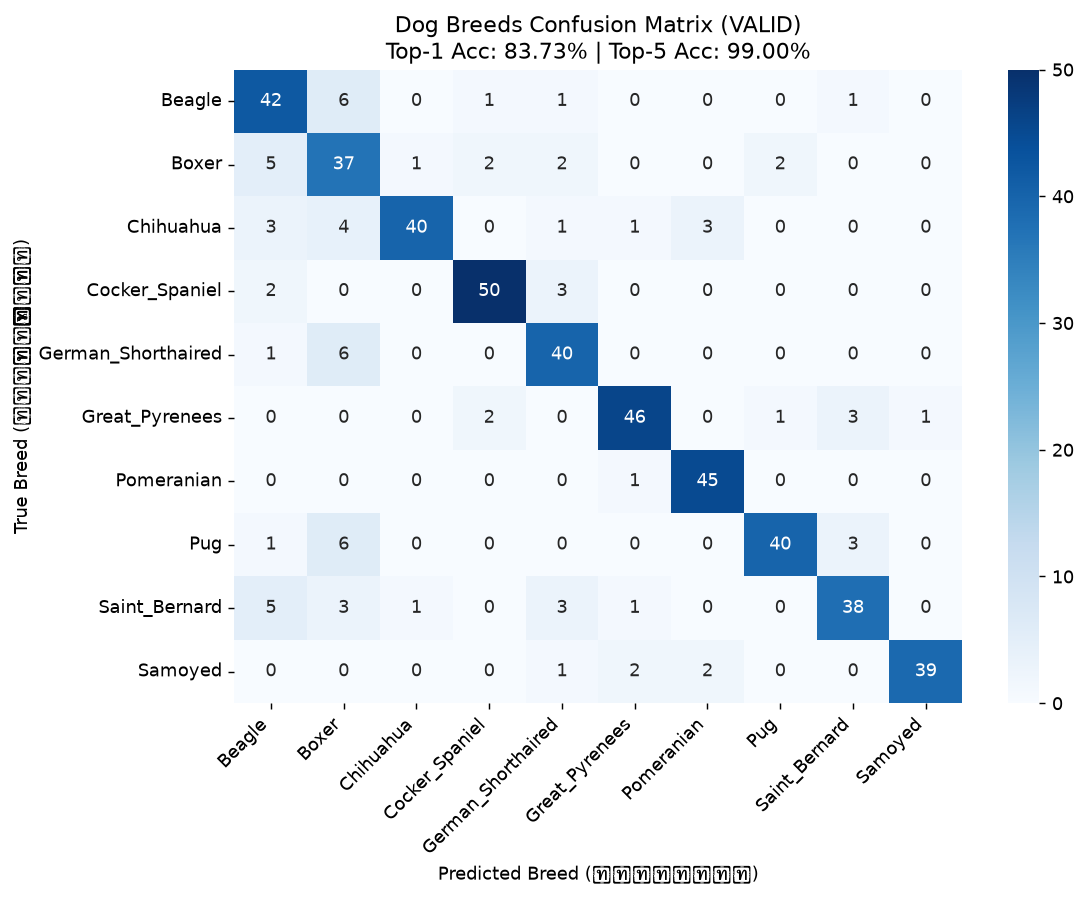

💾 บันทึกรูป Heatmap เรียบร้อยที่: C:\Users\perth\Downloads\My First Project.v1i.folder\confusion_matrix_valid.png


In [13]:
import os
import glob
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from ultralytics import YOLO
from sklearn.metrics import classification_report, confusion_matrix

def run_evaluation(weights_path=None, split="valid"):
    """
    ฟังก์ชันวัดผลโมเดลจำแนกสายพันธุ์สุนัขแบบเจาะลึก
    - weights_path : Path ไปยังไฟล์ best.pt
    - split : 'valid' หรือ 'test'
    """
    dataset_dir = r"C:\Users\perth\Downloads\My First Project.v1i.folder"
    eval_dir = os.path.join(dataset_dir, split)
    
    # เลือกรอบการเทรนล่าสุดอัตโนมัติ
    if weights_path is None:
        candidates = glob.glob(os.path.join(dataset_dir, "runs_breed_classification", "**", "best.pt"), recursive=True)
        weights_path = sorted(candidates, key=os.path.getmtime, reverse=True)[0]

    device = 0 if torch.cuda.is_available() else "cpu"
    model = YOLO(weights_path)
    classes = sorted([d for d in os.listdir(eval_dir) if os.path.isdir(os.path.join(eval_dir, d))])

    y_true, y_pred = [], []
    top5_correct, total_samples = 0, 0
    start_time = time.time()

    print(f"⏳ กำลังวัดผลโมเดลบนชุดข้อมูล {split.upper()} (GPU: {torch.cuda.get_device_name(0)})...")

    for cls_name in classes:
        for p in glob.glob(os.path.join(eval_dir, cls_name, "*.*")):
            res = model.predict(p, verbose=False, device=device)[0]
            top1_name = res.names[res.probs.top1]
            top5_names = [res.names[i] for i in res.probs.top5]

            y_true.append(cls_name)
            y_pred.append(top1_name)
            if cls_name in top5_names:
                top5_correct += 1
            total_samples += 1

    eval_time = time.time() - start_time
    fps = total_samples / eval_time

    # 1. คำนวณ Precision, Recall, F1-Score รายสายพันธุ์
    rep = classification_report(y_true, y_pred, target_names=classes, output_dict=True, digits=4)
    rows = []
    for c in classes:
        rows.append({
            "สายพันธุ์ (Breed)": c,
            "Precision": f"{rep[c]['precision']:.2%}",
            "Recall": f"{rep[c]['recall']:.2%}",
            "F1-Score": f"{rep[c]['f1-score']:.2%}",
            "จำนวนรูปจริง (Support)": int(rep[c]['support'])
        })
    df_report = pd.DataFrame(rows)

    print("\n" + "=" * 80)
    print("📋 [1] ตารางค่าวัดผลแยกรายสายพันธุ์ (Per-Class Performance)")
    print("=" * 80)
    print(df_report.to_string(index=False))

    # 2. ค่าวัดผลภาพรวม
    print("\n" + "=" * 80)
    print("🏆 [2] สรุปค่าวัดผลภาพรวมทั้งระบบ (Overall Metrics)")
    print("=" * 80)
    print(f"⭐ Top-1 Accuracy   : {rep['accuracy']:.2%}  (ทายอันดับ 1 ถูกต้อง)")
    print(f"⭐ Top-5 Accuracy   : {top5_correct/total_samples:.2%}  (สายพันธุ์จริงติด 1 ใน 5 อันดับแรก)")
    print(f"⭐ Macro Precision  : {rep['macro avg']['precision']:.2%}  (ความแม่นยำเฉลี่ย)")
    print(f"⭐ Macro Recall     : {rep['macro avg']['recall']:.2%}  (ความครอบคลุมเฉลี่ย)")
    print(f"⭐ Macro F1-Score   : {rep['macro avg']['f1-score']:.2%}  (ความสมดุลเฉลี่ยทุกสายพันธุ์)")
    print(f"⚡ ความเร็ว Inference: {fps:.1f} FPS ({total_samples} ภาพ ใช้เวลา {eval_time:.2f} วินาที)")

    # 3. จุดที่โมเดลทายสับสนมากที่สุด (Top Misclassifications)
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    confusions = [(classes[i], classes[j], cm[i][j]) for i in range(len(classes)) for j in range(len(classes)) if i != j and cm[i][j] > 0]
    confusions.sort(key=lambda x: x[2], reverse=True)

    print("\n" + "=" * 80)
    print("🔍 [3] 5 อันดับคู่สายพันธุ์ที่โมเดลทายสับสนมากที่สุด (Top Misclassifications)")
    print("=" * 80)
    for true_cls, pred_cls, count in confusions[:5]:
        print(f"⚠️  สายพันธุ์จริง: '{true_cls:<18}' ➔ โมเดลทายผิดเป็น: '{pred_cls:<18}' ({count} ภาพ)")

    # 4. พล็อต Confusion Matrix Heatmap
    plt.figure(figsize=(9, 7), dpi=130)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(f"Dog Breeds Confusion Matrix ({split.upper()})\nTop-1 Acc: {rep['accuracy']:.2%} | Top-5 Acc: {top5_correct/total_samples:.2%}")
    plt.xlabel("Predicted Breed (โมเดลทาย)")
    plt.ylabel("True Breed (สายพันธุ์จริง)")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    save_path = os.path.join(dataset_dir, f"confusion_matrix_{split}.png")
    plt.savefig(save_path)
    plt.show()
    print(f"💾 บันทึกรูป Heatmap เรียบร้อยที่: {save_path}")

# เรียกใช้งาน:
run_evaluation(split="valid")